Data Cleaning project

# New Section

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("raw_ecommerce_orders.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (225, 12)


,Order ID,Customer Name,Order Date,Product Name,Category,Quantity,Unit Price,City,Payment Method,Order Status,Customer Rating,Discount
0,ORD-1000,Isha Kulkarni,not available,Wireless Mouse,Electronics,1.0,2278.56,Delhi,UPI,Shipped,2.0,0.26
1,ORD-1001,Kabir Singh,2025-07-29,Wireless Mouse,Electronics,1.0,606.76,Bengaluru,Credit Card,Delivered,1.0,0.29
2,ORD-1002,Kabir Singh,2025-08-17,Jeans,Clothing,4.0,3962.41,Hyderabad,Credit Card,Shipped,NaN,0.04
3,ORD-1003,Meera Patil,2025-05-16,Gym Bag,Sports,5.0,1948.37,Bengaluru,Cash on Delivery,Delivered,2.0,0.28
4,ORD-1004,Rohan Desai,2025-07-13,Shampoo,Beauty,4.0,4140.39,Mumbai,UPI,Cancelled,1.0,0.13


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order ID         225 non-null    object 
 1   Customer Name    209 non-null    object 
 2   Order Date       225 non-null    object 
 3   Product Name     225 non-null    object 
 4   Category         225 non-null    object 
 5   Quantity         216 non-null    float64
 6   Unit Price       215 non-null    float64
 7   City             213 non-null    object 
 8   Payment Method   225 non-null    object 
 9   Order Status     225 non-null    object 
 10  Customer Rating  190 non-null    float64
 11  Discount         225 non-null    float64
dtypes: float64(4), object(8)
memory usage: 21.2+ KB


In [ ]:
df.describe()

,Quantity,Unit Price,Customer Rating,Discount
count,216.000000,215.000000,190.000000,225.000000
mean,3.064815,3383.531163,2.957895,0.172458
std,1.568724,7575.063529,1.435866,0.183504
min,-2.000000,171.830000,1.000000,0.000000
25%,2.000000,1177.335000,2.000000,0.090000
50%,3.000000,2536.940000,3.000000,0.160000
75%,4.000000,3932.465000,4.000000,0.230000
max,5.000000,79678.000000,5.000000,1.746607


In [ ]:
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Rows and columns: (225, 12)

Column names:
['Order ID', 'Customer Name', 'Order Date', 'Product Name', 'Category', 'Quantity', 'Unit Price', 'City', 'Payment Method', 'Order Status', 'Customer Rating', 'Discount']

Missing values:
Order ID            0
Customer Name      16
Order Date          0
Product Name        0
Category            0
Quantity            9
Unit Price         10
City               12
Payment Method      0
Order Status        0
Customer Rating    35
Discount            0
dtype: int64

Duplicate rows: 5


In [ ]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())

['order_id', 'customer_name', 'order_date', 'product_name', 'category', 'quantity', 'unit_price', 'city', 'payment_method', 'order_status', 'customer_rating', 'discount']


In [ ]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()

for col in [
    "category",
    "order_status",
    "payment_method",
    "city"
]:
    df[col] = (
        df[col]
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

print(df["category"].value_counts(dropna=False))
print(df["order_status"].value_counts(dropna=False))

category
Clothing          53
Beauty            50
Electronics       45
Home & Kitchen    41
Sports            36
Name: count, dtype: Int64
order_status
Cancelled    71
Returned     59
Delivered    56
Shipped      39
Name: count, dtype: Int64


In [ ]:
df["order_date"] = pd.to_datetime(
    df["order_date"],
    errors="coerce",
    dayfirst=True
)

numeric_columns = [
    "quantity",
    "unit_price",
    "customer_rating",
    "discount"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         225 non-null    string        
 1   customer_name    209 non-null    string        
 2   order_date       218 non-null    datetime64[ns]
 3   product_name     225 non-null    string        
 4   category         225 non-null    string        
 5   quantity         216 non-null    float64       
 6   unit_price       215 non-null    float64       
 7   city             213 non-null    string        
 8   payment_method   225 non-null    string        
 9   order_status     225 non-null    string        
 10  customer_rating  190 non-null    float64       
 11  discount         225 non-null    float64       
dtypes: datetime64[ns](1), float64(4), string(7)
memory usage: 21.2 KB


/tmp/ipykernel_4792/3428177566.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["order_date"] = pd.to_datetime(


In [ ]:
print("Invalid quantities:")
print((df["quantity"] <= 0).sum())

print("Invalid prices:")
print((df["unit_price"] <= 0).sum())

print("Invalid ratings:")
print(
    (~df["customer_rating"].between(1, 5)).sum()
)

print("Invalid discounts:")
print(
    (~df["discount"].between(0, 1)).sum()
)

Invalid quantities:
4
Invalid prices:
0
Invalid ratings:
35
Invalid discounts:
3


In [ ]:
print("Duplicate rows before cleaning:", df.duplicated().sum())

Duplicate rows before cleaning: 5


In [ ]:
df = df.drop_duplicates().copy()

print("Duplicate rows after cleaning:", df.duplicated().sum())

Duplicate rows after cleaning: 0


In [ ]:
text_columns = [
    "customer_name",
    "city",
    "category",
    "payment_method",
    "order_status"
]

for col in text_columns:
    df[col] = df[col].fillna("Unknown")

In [ ]:
quantity_median = df["quantity"].median()

df["quantity"] = (
    df["quantity"]
    .fillna(quantity_median)
    .round()
)

In [ ]:
print("Invalid dates:", df["order_date"].isna().sum())

df = df.dropna(subset=["order_date"]).copy()

Invalid dates: 7


In [ ]:
print(df.isnull().sum())

order_id            0
customer_name       0
order_date          0
product_name        0
category            0
quantity            0
unit_price         10
city                0
payment_method      0
order_status        0
customer_rating    34
discount            0
dtype: int64


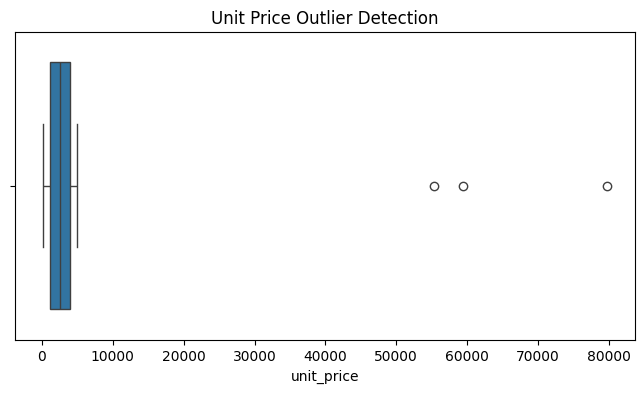

In [ ]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["unit_price"])

plt.title("Unit Price Outlier Detection")
plt.show()

In [ ]:
Q1 = df["unit_price"].quantile(0.25)

Q3 = df["unit_price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)

upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = df[
    (df["unit_price"] < lower_bound) |
    (df["unit_price"] > upper_bound)
]

print("Number of outliers:", len(outliers))

Lower bound: 0
Upper bound: 8065.16
Number of outliers: 3


In [ ]:
df["unit_price"] = df["unit_price"].clip(
    lower=lower_bound,
    upper=upper_bound
)

In [ ]:
encoded_df = pd.get_dummies(
    df,
    columns=[
        "category",
        "city",
        "payment_method",
        "order_status"
    ],
    dtype=int
)

encoded_df.head()

,order_id,customer_name,order_date,product_name,quantity,unit_price,customer_rating,discount,category_Beauty,category_Clothing,...,city_Pune,city_Unknown,payment_method_Cash On Delivery,payment_method_Credit Card,payment_method_Debit Card,payment_method_Upi,order_status_Cancelled,order_status_Delivered,order_status_Returned,order_status_Shipped
1,ORD-1001,Kabir Singh,2025-07-29,Wireless Mouse,1.0,606.76,1.0,0.29,0,0,...,0,0,0,1,0,0,0,1,0,0
2,ORD-1002,Kabir Singh,2025-08-17,Jeans,4.0,3962.41,NaN,0.04,0,1,...,0,0,0,1,0,0,0,0,0,1
3,ORD-1003,Meera Patil,2025-05-16,Gym Bag,5.0,1948.37,2.0,0.28,0,0,...,0,0,1,0,0,0,0,1,0,0
4,ORD-1004,Rohan Desai,2025-07-13,Shampoo,4.0,4140.39,1.0,0.13,1,0,...,0,0,0,0,0,1,1,0,0,0
5,ORD-1005,Aarav Shah,2025-03-10,USB Hub,3.0,2839.74,1.0,0.02,0,0,...,0,0,1,0,0,0,1,0,0,0


In [ ]:
df["revenue"] = (
    df["quantity"] *
    df["unit_price"] *
    (1 - df["discount"])
).round(2)

df[[
    "order_id",
    "quantity",
    "unit_price",
    "discount",
    "revenue"
]].head()

,order_id,quantity,unit_price,discount,revenue
1,ORD-1001,1.0,606.76,0.29,430.80
2,ORD-1002,4.0,3962.41,0.04,15215.65
3,ORD-1003,5.0,1948.37,0.28,7014.13
4,ORD-1004,4.0,4140.39,0.13,14408.56
5,ORD-1005,3.0,2839.74,0.02,8348.84


In [ ]:
print("Final dataset shape:", df.shape)

print("Duplicate rows:", df.duplicated().sum())

print("Total missing cells:", df.isnull().sum().sum())

print("Invalid quantities:", (df["quantity"] <= 0).sum())

print("Invalid prices:", (df["unit_price"] <= 0).sum())

print("\nData types:")
print(df.dtypes)

print("\nSummary statistics:")
display(df.describe(include="all").T)

Final dataset shape: (213, 13)
Duplicate rows: 0
Total missing cells: 54
Invalid quantities: 4
Invalid prices: 0

Data types:
order_id           string[python]
customer_name      string[python]
order_date         datetime64[ns]
product_name       string[python]
category           string[python]
quantity                  float64
unit_price                float64
city               string[python]
payment_method     string[python]
order_status       string[python]
customer_rating           float64
discount                  float64
revenue                   float64
dtype: object

Summary statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,213,213,ORD-1001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,213,7,Isha Kulkarni,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,213,NaN,NaN,NaN,2025-06-01 05:51:32.957746432,2025-01-03 00:00:00,2025-03-20 00:00:00,2025-06-06 00:00:00,2025-08-20 00:00:00,2025-10-25 00:00:00,NaN
product_name,213,20,Face Wash,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,213,5,Clothing,49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,213.0,NaN,NaN,NaN,3.037559,-2.0,2.0,3.0,4.0,5.0,1.541409
unit_price,203.0,NaN,NaN,NaN,2587.733103,171.83,1177.335,2536.94,3932.465,8065.16,1604.289162
city,213,7,Bengaluru,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,213,4,Credit Card,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_status,213,4,Cancelled,68,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df = df.sort_values(
    ["order_date", "order_id"]
).reset_index(drop=True)

df.to_csv(
    "cleaned_ecommerce_orders.csv",
    index=False,
    date_format="%Y-%m-%d"
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


Task 2
Exploratory data Analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
DATA_PATH = "/content/cleaned_ecommerce_orders.csv"  # Upload CSV to Colab Files first
try: df = pd.read_csv(DATA_PATH)
except FileNotFoundError: df = pd.read_csv("cleaned_ecommerce_orders.csv")
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
for c in ["quantity", "unit_price", "discount", "customer_rating", "revenue"]: df[c] = pd.to_numeric(df[c], errors="coerce")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (213, 13)


,order_id,customer_name,order_date,product_name,category,quantity,unit_price,city,payment_method,order_status,customer_rating,discount,revenue
0,ORD-1017,Unknown,2025-01-03,Gym Bag,Sports,5.0,3966.58,Unknown,Credit Card,Delivered,NaN,0.20,15866.32
1,ORD-1158,Isha Kulkarni,2025-01-03,T-Shirt,Clothing,3.0,1627.82,Chennai,Credit Card,Cancelled,4.0,0.13,4248.61
2,ORD-1198,Rohan Desai,2025-01-03,Yoga Mat,Sports,3.0,1498.41,Bengaluru,Credit Card,Cancelled,NaN,0.21,3551.23
3,ORD-1178,Kabir Singh,2025-01-04,Shampoo,Beauty,2.0,1163.93,Hyderabad,Credit Card,Returned,5.0,0.16,1955.40
4,ORD-1068,Anaya Joshi,2025-01-05,Skipping Rope,Sports,5.0,1263.83,Bengaluru,Debit Card,Shipped,5.0,0.04,6066.38


In [ ]:
df.info()
display(df.describe(include="all").T)
missing = pd.DataFrame({"missing_count":df.isna().sum(), "missing_percent":(df.isna().mean()*100).round(2), "dtype":df.dtypes.astype(str)}).sort_values("missing_percent",ascending=False)
display(missing)
print("Duplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 213 entries, 0 to 212
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         213 non-null    object        
 1   customer_name    213 non-null    object        
 2   order_date       213 non-null    datetime64[ns]
 3   product_name     213 non-null    object        
 4   category         213 non-null    object        
 5   quantity         213 non-null    float64       
 6   unit_price       203 non-null    float64       
 7   city             213 non-null    object        
 8   payment_method   213 non-null    object        
 9   order_status     213 non-null    object        
 10  customer_rating  179 non-null    float64       
 11  discount         213 non-null    float64       
 12  revenue          203 non-null    float64       
dtypes: datetime64[ns](1), float64(5), object(7)
memory usage: 21.8+ KB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,213,213,ORD-1017,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,213,7,Isha Kulkarni,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,213,NaN,NaN,NaN,2025-06-01 05:51:32.957746432,2025-01-03 00:00:00,2025-03-20 00:00:00,2025-06-06 00:00:00,2025-08-20 00:00:00,2025-10-25 00:00:00,NaN
product_name,213,20,Face Wash,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,213,5,Clothing,49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,213.0,NaN,NaN,NaN,3.037559,-2.0,2.0,3.0,4.0,5.0,1.541409
unit_price,203.0,NaN,NaN,NaN,2587.733103,171.83,1177.335,2536.94,3932.465,8065.16,1604.289162
city,213,7,Bengaluru,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,213,4,Credit Card,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_status,213,4,Cancelled,68,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_percent,dtype
customer_rating,34,15.96,float64
unit_price,10,4.69,float64
revenue,10,4.69,float64
customer_name,0,0.00,object
order_id,0,0.00,object
category,0,0.00,object
product_name,0,0.00,object
order_date,0,0.00,datetime64[ns]
quantity,0,0.00,float64
payment_method,0,0.00,object


Duplicate rows: 0


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].describe().T)
display(df.select_dtypes(exclude=np.number).describe().T)


,count,mean,std,min,25%,50%,75%,max
quantity,213.0,3.037559,1.541409,-2.00,2.000,3.00,4.000,5.000000
unit_price,203.0,2587.733103,1604.289162,171.83,1177.335,2536.94,3932.465,8065.160000
customer_rating,179.0,2.960894,1.435361,1.00,2.000,3.00,4.000,5.000000
discount,213.0,0.173207,0.187775,0.00,0.080,0.16,0.230,1.746607
revenue,203.0,6563.200985,6393.793995,-17812.39,2147.430,4571.99,10153.590,33470.410000


,count,mean,min,25%,50%,75%,max
order_date,213,2025-06-01 05:51:32.957746432,2025-01-03 00:00:00,2025-03-20 00:00:00,2025-06-06 00:00:00,2025-08-20 00:00:00,2025-10-25 00:00:00


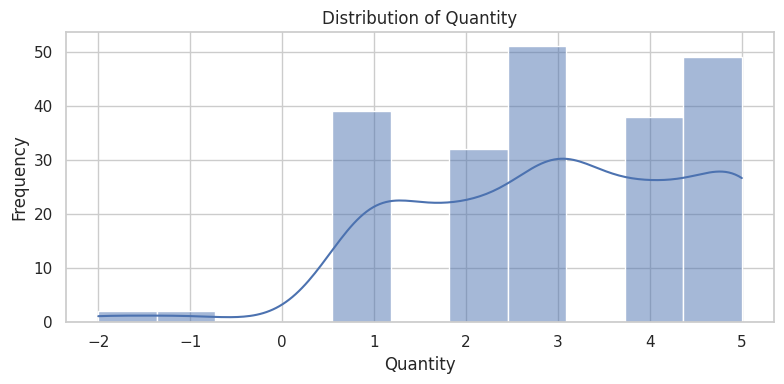

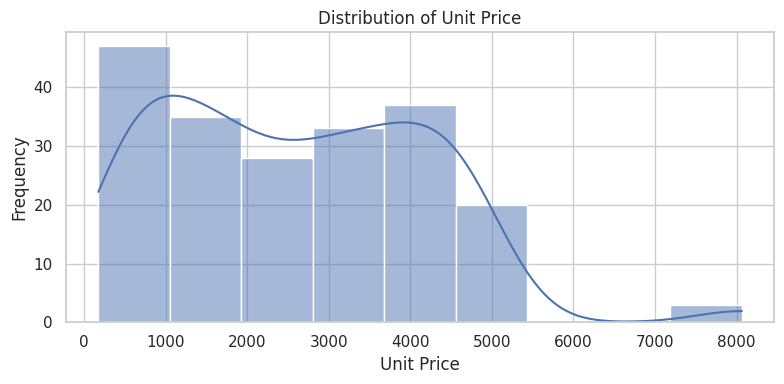

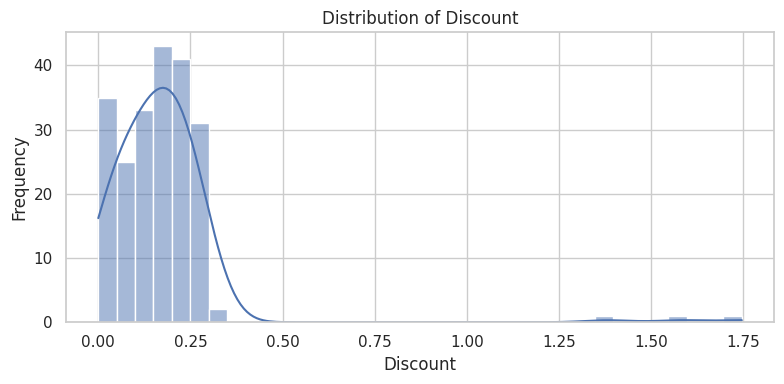

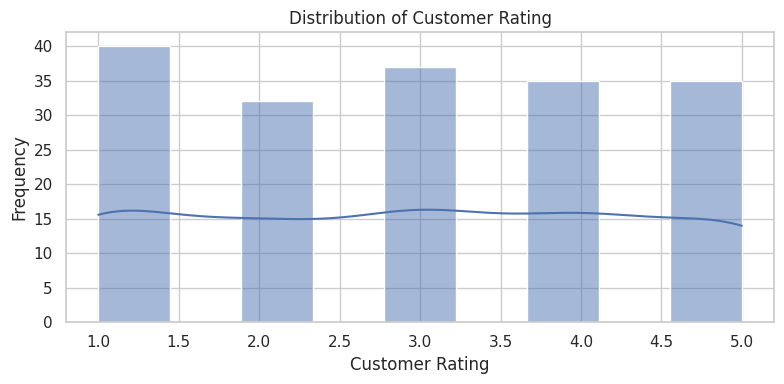

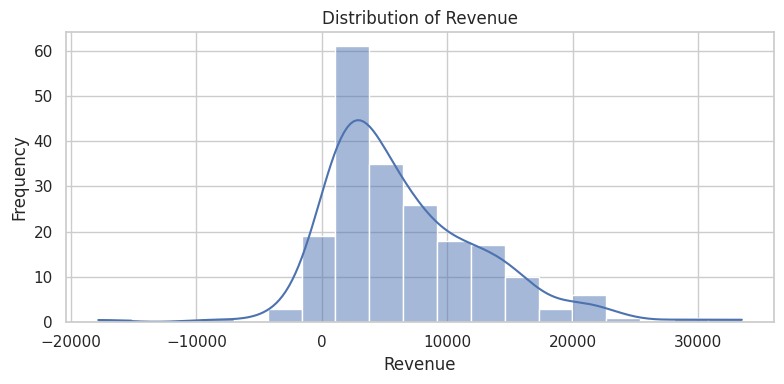

In [ ]:
numeric_cols = [c for c in ["quantity","unit_price","discount","customer_rating","revenue"] if c in df.columns]
for c in numeric_cols:
    fig, ax = plt.subplots(figsize=(8,4))
    sns.histplot(data=df, x=c, kde=True, ax=ax)
    ax.set_title(f"Distribution of {c.replace('_',' ').title()}")
    ax.set_xlabel(c.replace('_',' ').title()); ax.set_ylabel("Frequency")
    plt.tight_layout(); plt.show()


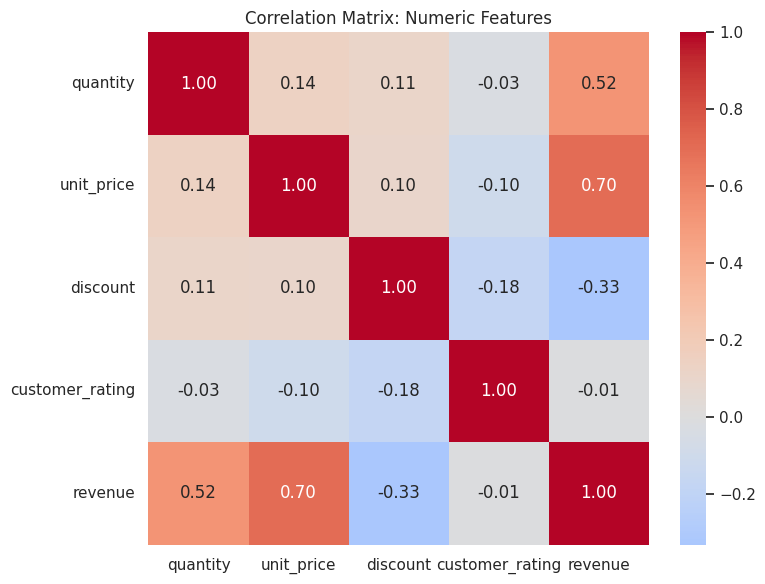

,quantity,unit_price,discount,customer_rating,revenue
quantity,1.000000,0.136759,0.105486,-0.028437,0.524940
unit_price,0.136759,1.000000,0.098999,-0.103708,0.701922
discount,0.105486,0.098999,1.000000,-0.175019,-0.332813
customer_rating,-0.028437,-0.103708,-0.175019,1.000000,-0.011739
revenue,0.524940,0.701922,-0.332813,-0.011739,1.000000


In [ ]:
corr = df[numeric_cols].corr(numeric_only=True)
plt.figure(figsize=(8,6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix: Numeric Features"); plt.tight_layout(); plt.show()
display(corr)


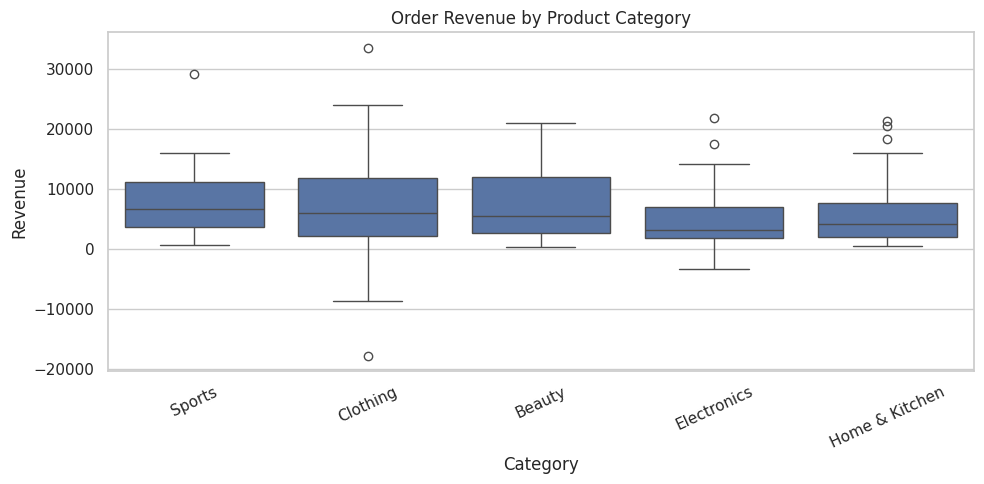

In [ ]:
plt.figure(figsize=(10,5)); sns.boxplot(data=df, x="category", y="revenue")
plt.title("Order Revenue by Product Category"); plt.xlabel("Category"); plt.ylabel("Revenue")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()


,revenue,orders,units
month,,,
2025-01-01,124221.31,22,59.0
2025-02-01,197626.53,24,64.0
2025-03-01,128688.83,15,46.0
2025-04-01,136236.31,23,74.0
2025-05-01,124120.83,21,76.0
2025-06-01,99387.33,19,55.0
2025-07-01,131994.88,25,70.0
2025-08-01,203576.18,25,87.0
2025-09-01,102982.61,20,56.0


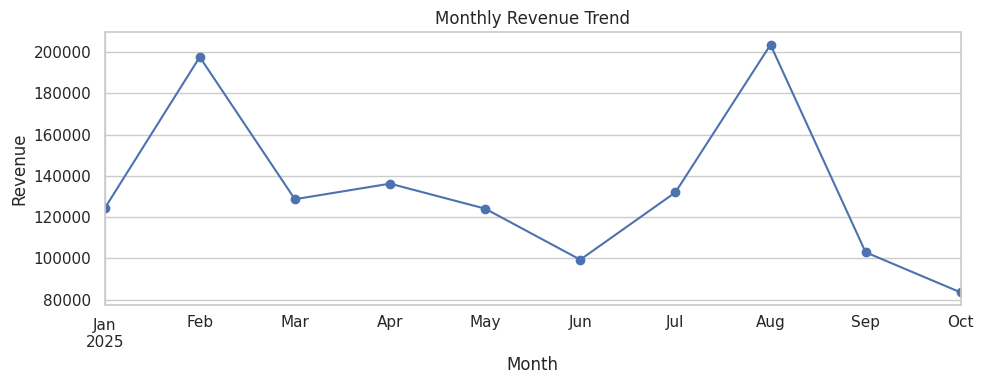

In [ ]:
time_df = df.dropna(subset=["order_date"]).copy()
time_df["month"] = time_df.order_date.dt.to_period("M").dt.to_timestamp()
monthly = time_df.groupby("month").agg(revenue=("revenue","sum"), orders=("order_id","nunique"), units=("quantity","sum")).sort_index()
display(monthly)
monthly.revenue.plot(marker="o", figsize=(10,4)); plt.title("Monthly Revenue Trend"); plt.xlabel("Month"); plt.ylabel("Revenue"); plt.tight_layout(); plt.show()


,orders,units_sold,total_revenue,avg_order_revenue,avg_rating
category,,,,,
Clothing,49,145.0,341370.83,7111.892292,2.976190
Beauty,47,152.0,298905.02,6951.279535,2.902439
Home & Kitchen,41,127.0,253962.78,6511.866154,2.911765
Sports,35,116.0,251290.47,7852.827188,2.851852
Electronics,41,107.0,186800.70,4556.114634,3.142857


,orders,revenue,units
city,,,
Delhi,33,238541.98,107.0
Pune,35,231450.90,108.0
Mumbai,35,230178.96,109.0
Chennai,37,216430.29,109.0
Bengaluru,40,205841.43,123.0
Hyderabad,21,141804.56,53.0
Unknown,12,68081.68,38.0


,orders,units,revenue
product_name,,,
T-Shirt,15,47.0,138502.33
Face Wash,16,50.0,117954.87
Mixer,14,47.0,108962.75
Jeans,12,35.0,102362.99
Gym Bag,14,46.0,87032.25
USB Hub,12,33.0,84997.07
Bedsheet,15,46.0,81396.95
Sunscreen,13,43.0,75986.13
Skipping Rope,9,31.0,72398.03


,orders,revenue
order_status,,
Cancelled,68,462294.88
Returned,58,372875.60
Delivered,54,306287.42
Shipped,33,190871.90


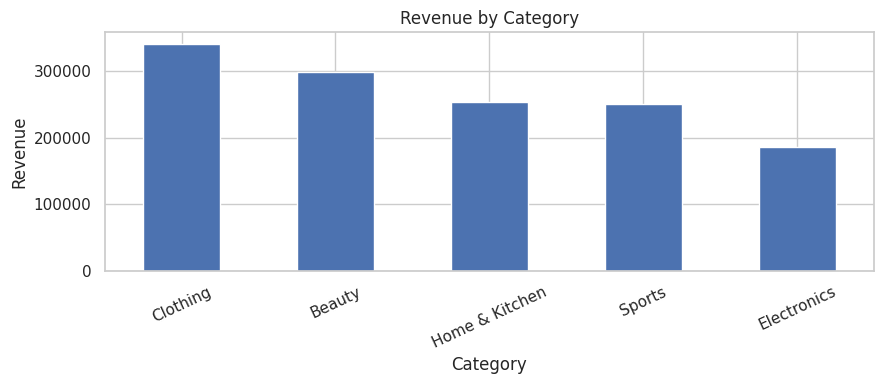

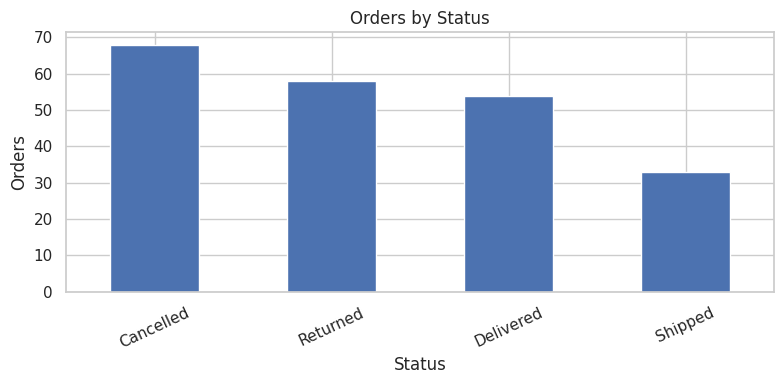

In [ ]:
category_summary = df.groupby("category").agg(orders=("order_id","nunique"), units_sold=("quantity","sum"), total_revenue=("revenue","sum"), avg_order_revenue=("revenue","mean"), avg_rating=("customer_rating","mean")).sort_values("total_revenue",ascending=False)
display(category_summary)
city_summary = df.groupby("city").agg(orders=("order_id","nunique"), revenue=("revenue","sum"), units=("quantity","sum")).sort_values("revenue",ascending=False); display(city_summary)
product_summary = df.groupby("product_name").agg(orders=("order_id","nunique"), units=("quantity","sum"), revenue=("revenue","sum")).sort_values("revenue",ascending=False); display(product_summary.head(10))
status_summary = df.groupby("order_status").agg(orders=("order_id","nunique"), revenue=("revenue","sum")).sort_values("orders",ascending=False); display(status_summary)
category_summary.total_revenue.plot(kind="bar",figsize=(9,4),title="Revenue by Category"); plt.xlabel("Category"); plt.ylabel("Revenue"); plt.xticks(rotation=25); plt.tight_layout(); plt.show()
status_summary.orders.plot(kind="bar",figsize=(8,4),title="Orders by Status"); plt.xlabel("Status"); plt.ylabel("Orders"); plt.xticks(rotation=25); plt.tight_layout(); plt.show()


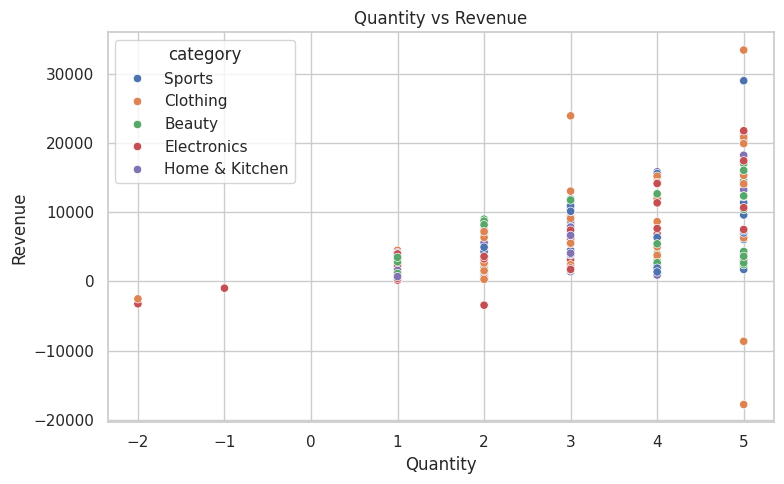

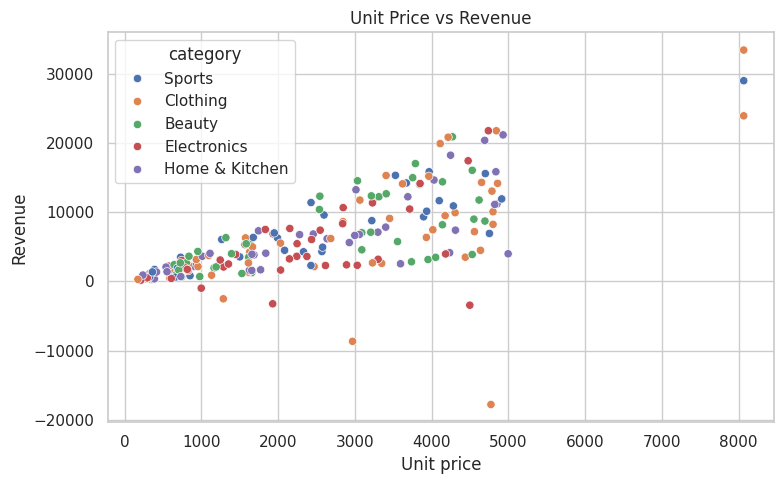

In [ ]:
plt.figure(figsize=(8,5)); sns.scatterplot(data=df,x="quantity",y="revenue",hue="category"); plt.title("Quantity vs Revenue"); plt.xlabel("Quantity"); plt.ylabel("Revenue"); plt.tight_layout(); plt.show()
plt.figure(figsize=(8,5)); sns.scatterplot(data=df,x="unit_price",y="revenue",hue="category"); plt.title("Unit Price vs Revenue"); plt.xlabel("Unit price"); plt.ylabel("Revenue"); plt.tight_layout(); plt.show()


In [ ]:
total_revenue = df.revenue.sum(); total_orders = df.order_id.nunique(); avg_order_value = total_revenue/total_orders if total_orders else np.nan; total_units = df.quantity.sum()
top_category = df.groupby("category").revenue.sum().idxmax(); top_product = df.groupby("product_name").revenue.sum().idxmax(); top_city = df.groupby("city").revenue.sum().idxmax()
display(pd.DataFrame({"Metric":["Rows","Unique orders","Total revenue","Average revenue per order","Total units sold","Top category","Top product","Top city"],"Value":[len(df),total_orders,round(total_revenue,2),round(avg_order_value,2),int(total_units),top_category,top_product,top_city]}))


,Metric,Value
0,Rows,213
1,Unique orders,213
2,Total revenue,1332329.8
3,Average revenue per order,6255.07
4,Total units sold,647
5,Top category,Clothing
6,Top product,T-Shirt
7,Top city,Delhi


In [ ]:
cat_rev = df.groupby("category").revenue.sum().sort_values(ascending=False); prod_rev = df.groupby("product_name").revenue.sum().sort_values(ascending=False); city_rev = df.groupby("city").revenue.sum().sort_values(ascending=False); status_counts = df.order_status.value_counts()
corr_q_rev = df[["quantity","revenue"]].corr().iloc[0,1]; missing_rating_pct = df.customer_rating.isna().mean()*100
insights = [f"**Category performance:** {cat_rev.index[0]} leads revenue ({cat_rev.iloc[0]:,.2f}); review availability and top products.", f"**Product concentration:** {prod_rev.index[0]} is the top product by revenue ({prod_rev.iloc[0]:,.2f}); monitor stockouts and concentration risk.", f"**Geographic performance:** {city_rev.index[0]} has the highest revenue ({city_rev.iloc[0]:,.2f}); compare spend, delivery performance, and order volume across cities.", f"**Order status:** {status_counts.index[0]} is most common ({status_counts.iloc[0]} orders); analyze cancellation and return rates separately.", f"**Rating coverage:** {missing_rating_pct:.1f}% of ratings are missing; improve feedback collection and never treat missing ratings as zero.", f"**Correlation caveat:** Quantity/revenue correlation is {corr_q_rev:.2f}; it is partly mathematical because quantity contributes to revenue."]
display(Markdown("\n\n".join(f"{i+1}. {x}" for i,x in enumerate(insights))))
recommendations = ["Prioritize high-revenue categories while checking profit margins.", "Investigate cancellation/return patterns by product, city, and payment method.", "Track revenue, order count, and average order value together each month.", "Improve customer-rating capture and monitor response rates.", "Validate date coverage and business definitions before decisions."]
display(Markdown("### Recommendations\n"+"\n".join(f"- {x}" for x in recommendations)))


1. **Category performance:** Clothing leads revenue (341,370.83); review availability and top products.

2. **Product concentration:** T-Shirt is the top product by revenue (138,502.33); monitor stockouts and concentration risk.

3. **Geographic performance:** Delhi has the highest revenue (238,541.98); compare spend, delivery performance, and order volume across cities.

4. **Order status:** Cancelled is most common (68 orders); analyze cancellation and return rates separately.

5. **Rating coverage:** 16.0% of ratings are missing; improve feedback collection and never treat missing ratings as zero.

6. **Correlation caveat:** Quantity/revenue correlation is 0.52; it is partly mathematical because quantity contributes to revenue.

### Recommendations
- Prioritize high-revenue categories while checking profit margins.
- Investigate cancellation/return patterns by product, city, and payment method.
- Track revenue, order count, and average order value together each month.
- Improve customer-rating capture and monitor response rates.
- Validate date coverage and business definitions before decisions.

 Conclusion

This EDA includes statistical summaries, histograms with KDE, a correlation heatmap, category box plots, monthly trends, grouped analysis, and scatter plots. Add margin, shipping cost, refunds, and delivery time to assess profitability and service quality.